# Part A — Sobel Edge Detection preprocessing pipeline

A classical **Sobel Edge Detection** preprocessing pipeline for cervical
colposcopy images. This notebook replaces the former QI-SABP
(quantum-inspired) preprocessing: **all QI-SABP techniques and
configuration have been removed** and rewritten around a single,
standard edge-detection operator.

## What was removed (former QI-SABP machinery)

* Quantum-inspired fused saliency (Sobel 0.25 + spectral residual 0.30 +
  multi-scale contrast 0.30 + local entropy 0.15 + optional whiteness
  channel).
* Soft saliency mask (rank/CDF normalisation, sigmoid gain, per-image
  coverage solver), hard-mask hole filling, rim/main-component rules,
  min-area filter, glare mask (V>250 / S<25).
* Edge-aware continuous bit allocation (8/6 salient vs 4/4 non-salient
  bits + edge boost), dithered quantization, YCbCr 4:2:0 chroma
  subsampling, soft-blend.
* NLM pre-denoise, bilateral post-filter, partial histogram matching.

## What the Sobel Edge Detection preprocessing does

1. **Step 1 — Unsharp-mask sharpen** (unchanged, shared across the
   suite): `amount=0.8`, `ksize=5`.
2. **Step 2 — Sobel Edge Detection + edge enhancement**:
   * Gradients `gx`, `gy` via `cv2.Sobel` (`ksize` = 3 or 5) on the
     grayscale of the (sharpened) RGB image, L1-normalised so the
     magnitude `G = |gx| + |gy|` reads in gray-level units
     (`G ≈ step_height / 2` at a clean step edge).
   * Binary edge gate: `G >= SOBEL_TAU` inside the field of view (FOV).
   * Edge-enhanced output: `out = clip(orig + SOBEL_GAIN * G, 0, 255)`
     on gated pixels, original elsewhere. The gradient magnitude is
     added equally to R, G and B, so hue is preserved and only local
     contrast on strong edges is boosted.
   * FOV guard: pixels outside the FOV are copied verbatim from the
     input (same output contract as the previous pipeline).

## Output

The pipeline returns a **uint8 RGB image, same shape as the input**.
It is NOT a compression scheme and produces no byte stream: the output
stays at full 8-bit depth, so the nominal luma bit depth (metric m11,
"Luma bits") is 8.0 for every row. It is an *enhancement* technique:
the validation in Part B therefore measures how far the enhanced image
sits from the original (distortion, colour, structure, quality
diagnostics) — a lower PSNR here means *stronger* enhancement, not
worse reconstruction.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-technique merge notebook).
* It does NOT demonstrate a clinical benefit on this single patient.


In [1]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, glob, random, warnings, platform

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter

from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV artefacts.
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"Sobel Edge Detection Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


Sobel Edge Detection Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   ALL former QI-SABP configuration (saliency fusion weights, soft
#   mask / coverage, bit allocation, dither, YCbCr 4:2:0, NLM,
#   bilateral, histogram match, glare mask, rim rules) is REMOVED.
#   The only Step-2 technique is Sobel Edge Detection.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1, shared across the suite -- unchanged) ----
# This setting comes from Step 1 and is shared across the notebooks in
# the suite (amount=0.8, ksize=5).
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Sobel Edge Detection (Step 2 -- the ONLY preprocessing technique) ----
# Gradients: gx, gy = cv2.Sobel(gray, CV_64F, ...) with the separable
# kernel L1-normalised, so G = |gx| + |gy| is in gray-level units
# (G ~ step_height / 2 at a clean step edge, i.e. TAU=50 gates local
# steps of roughly >= 100 gray levels).
#
#   SOBEL_KSIZE   : Sobel kernel size (3 or 5; made odd automatically).
#   SOBEL_TAU     : edge-gate threshold -- pixels with G >= TAU inside
#                   the FOV are enhanced.
#   SOBEL_GAIN    : enhancement strength -- out = orig + GAIN * G on
#                   gated pixels (added equally to R, G and B so hue is
#                   preserved).
#   USE_FOV_GUARD : pixels outside the FOV are copied verbatim from the
#                   input (same contract as the previous pipeline).
SOBEL_KSIZE      = 3
SOBEL_TAU        = 50
SOBEL_GAIN       = 0.5
USE_FOV_GUARD    = True

# Defaults registry for the Step 4 validator wrapper (fixed
# module-level configuration; no tuning on a single patient).
SOBEL_DEFAULTS = {"ksize": SOBEL_KSIZE, "tau": SOBEL_TAU, "gain": SOBEL_GAIN}

# ---- Ablation variants for Part B (like-for-like) ----
# Only ksize / tau change across rows; SOBEL_GAIN stays fixed so the
# rows are directly comparable. The first entry is the default config.
SOBEL_VARIANTS = [
    ("Sobel k3 tau50 (default)", {"ksize": 3, "tau": 50, "gain": SOBEL_GAIN}),
    ("Sobel k3 tau30",           {"ksize": 3, "tau": 30, "gain": SOBEL_GAIN}),
    ("Sobel k3 tau80",           {"ksize": 3, "tau": 80, "gain": SOBEL_GAIN}),
    ("Sobel k5 tau30",           {"ksize": 5, "tau": 30, "gain": SOBEL_GAIN}),
    ("Sobel k5 tau50",           {"ksize": 5, "tau": 50, "gain": SOBEL_GAIN}),
]

# ---- Nominal luma bit depth of the output (metric m11 "Luma bits") ----
# The Sobel output is full uint8 RGB -- no bit-depth reduction is
# applied, so the nominal luma bit depth is 8.0 for every row
# (including the Identity reference).
NOMINAL_LUMA_BITS = 8.0

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation batch (Step 4) ----
SUBSET_PER_CLASS = None        # None = load every image

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  Sobel Edge Detection: ksize={SOBEL_KSIZE}, tau={SOBEL_TAU}, "
      f"gain={SOBEL_GAIN}, fov_guard={USE_FOV_GUARD}")
print(f"  ablation variants = {len(SOBEL_VARIANTS)} (+ Identity reference)")
for _name, _p in SOBEL_VARIANTS:
    print(f"    - {_name:28s} {_p}")
print(f"  nominal luma bits (m11) = {NOMINAL_LUMA_BITS}")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  Sobel Edge Detection: ksize=3, tau=50, gain=0.5, fov_guard=True
  ablation variants = 5 (+ Identity reference)
    - Sobel k3 tau50 (default)     {'ksize': 3, 'tau': 50, 'gain': 0.5}
    - Sobel k3 tau30               {'ksize': 3, 'tau': 30, 'gain': 0.5}
    - Sobel k3 tau80               {'ksize': 3, 'tau': 80, 'gain': 0.5}
    - Sobel k5 tau30               {'ksize': 5, 'tau': 30, 'gain': 0.5}
    - Sobel k5 tau50               {'ksize': 5, 'tau': 50, 'gain': 0.5}
  nominal luma bits (m11) = 8.0


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the saliency-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


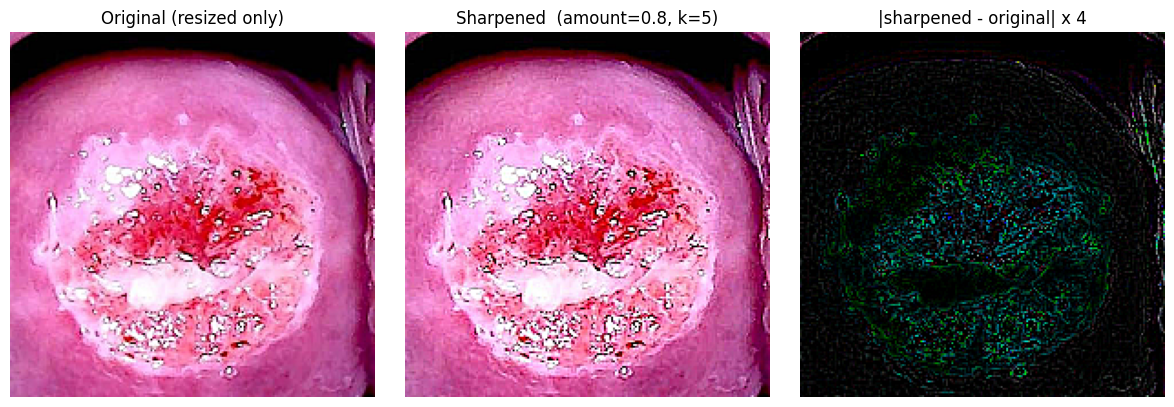

In [4]:
# ============================================================
# Cell 1.4 — Sharpen before/after visualisation
# ============================================================
def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb
    sharpened = sharpen(raw_resized)
    diff = np.clip(sharpened.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw_resized);    ax[0].set_title("Original (resized only)")
    ax[0].axis("off")
    ax[1].imshow(sharpened);      ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")  # x4 to make the high-pass visible
    ax[2].set_title("|sharpened - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    # Use first sharpened image (X_raw is already sharpened) — rebuild
    # original = synthetic / dataset image before sharpen for comparison.
    show_sharpen_effect(img_rgb=X_raw[0])
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(sharpen(demo));      ax[1].set_title("Sharpened");      ax[1].axis("off")
    plt.tight_layout(); plt.show()


In [5]:
# ============================================================
# Cell 2.1 -- Sobel Edge Detection core + edge enhancement
#
#   compute_fov_mask(img_rgb)  -> bool FOV mask (shared with Step 4)
#   sobel_gradients(img_rgb)   -> gx, gy, G, l1  (G in gray-level units)
#   sobel_edge_map(img_rgb)    -> binary edge mask (G >= tau)
#   sobel_edge_enhance(...)    -> (uint8 RGB enhanced image, artefacts)
#
# Output contract (same as the previous pipeline): uint8 RGB, same
# shape as the input; pixels outside the FOV are copied verbatim.
# ============================================================

def _sobel_l1_norm(ksize):
    """L1 norm of the separable Sobel kernel, so G reads in gray levels."""
    kx, ky = cv2.getDerivKernels(1, 0, int(ksize), normalize=False)
    return float(np.abs(kx).sum() * np.abs(ky).sum())


def compute_fov_mask(img_rgb, thr=15):
    """FOV mask: largest bright component, holes filled, convex hull
    closed. Shared by Part A (FOV guard) and Step 4 (metric region) so
    both use the exact same definition."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                     cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov


def sobel_gradients(img_rgb, ksize=None):
    """Sobel gradients of the grayscale image.

    Returns (gx, gy, G, l1): gx/gy are the L1-normalised derivatives and
    G = |gx| + |gy| approximates the local intensity step in gray levels
    (G ~ step_height / 2 at a clean step edge).
    """
    ksize = SOBEL_KSIZE if ksize is None else int(ksize)
    if ksize % 2 == 0:
        ksize += 1                      # cv2.Sobel requires odd ksize
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float64)
    l1 = _sobel_l1_norm(ksize)
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=ksize) / l1
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=ksize) / l1
    G = np.abs(gx) + np.abs(gy)
    return gx, gy, G, l1


def sobel_edge_map(img_rgb, tau=None, ksize=None):
    """Binary Sobel edge mask: G >= tau (whole frame, no FOV filter)."""
    tau = SOBEL_TAU if tau is None else float(tau)
    _, _, G, _ = sobel_gradients(img_rgb, ksize=ksize)
    return (G >= tau)


def sobel_edge_enhance(img_rgb, ksize=None, tau=None, gain=None,
                       fov_mask=None, use_fov_guard=None):
    """Sobel Edge Detection preprocessing (the Step-2 technique).

    out = clip(orig + GAIN * G, 0, 255) on edge-gated pixels (G >= TAU),
    original elsewhere. The gradient magnitude is added equally to R, G
    and B so hue is preserved. Pixels outside the FOV are copied
    verbatim when the FOV guard is on.

    Returns (out_uint8_RGB, artefacts_dict).
    """
    ksize = SOBEL_KSIZE if ksize is None else int(ksize)
    if ksize % 2 == 0:
        ksize += 1
    tau   = SOBEL_TAU   if tau   is None else float(tau)
    gain  = SOBEL_GAIN  if gain  is None else float(gain)
    use_fov_guard = USE_FOV_GUARD if use_fov_guard is None else bool(use_fov_guard)

    img_rgb = np.asarray(img_rgb)
    if img_rgb.dtype != np.uint8:
        img_rgb = np.clip(img_rgb, 0, 255).astype(np.uint8)

    if fov_mask is None:
        fov_mask = compute_fov_mask(img_rgb)
    fov_mask = np.asarray(fov_mask, dtype=bool)

    gx, gy, G, l1 = sobel_gradients(img_rgb, ksize=ksize)
    gate = (G >= tau) & fov_mask if use_fov_guard else (G >= tau)

    out = img_rgb.astype(np.float64).copy()
    add = gain * G[gate]
    out[gate] = np.clip(out[gate] + add[:, None], 0, 255)   # add to R,G,B equally
    out = out.astype(np.uint8)

    # FOV guard: outside-FOV pixels MUST be identical to the input.
    if use_fov_guard:
        out[~fov_mask] = img_rgb[~fov_mask]

    artefacts = {
        'img_original': img_rgb,
        'img_processed': out,
        'G': G,
        'gx': gx,
        'gy': gy,
        'edge_mask': gate,
        'fov_mask': fov_mask,
        'ksize': ksize,
        'tau': tau,
        'gain': gain,
        'l1_norm': l1,
        'edge_coverage_fov': (float(gate[fov_mask].mean())
                              if fov_mask.any() else float('nan')),
    }
    return out, artefacts


# ---- Sanity check on the first image ----
if len(X_raw) > 0:
    _fov0 = compute_fov_mask(X_raw[0])
    _out0, _art0 = sobel_edge_enhance(X_raw[0], fov_mask=_fov0)
    print("Sobel Edge Detection preprocessing sanity check (image 0):")
    print(f"  img_original  shape={_art0['img_original'].shape} "
          f"dtype={_art0['img_original'].dtype}")
    print(f"  img_processed shape={_art0['img_processed'].shape} "
          f"dtype={_art0['img_processed'].dtype}")
    print(f"  G range=[{_art0['G'].min():.2f}, {_art0['G'].max():.2f}] gray levels "
          f"(ksize={_art0['ksize']}, kernel L1 norm={_art0['l1_norm']:.0f})")
    print(f"  edge gate (G >= {_art0['tau']}) covers "
          f"{100 * _art0['edge_coverage_fov']:.2f}% of the FOV")
    _outside_equal = np.array_equal(_art0['img_processed'][~_art0['fov_mask']],
                                    _art0['img_original'][~_art0['fov_mask']])
    print(f"  outside-FOV pixels identical to input: {_outside_equal}  (must be True)")
    _mse = np.mean((_art0['img_original'].astype(np.float64)
                    - _art0['img_processed'].astype(np.float64)) ** 2)
    _psnr = 10 * np.log10(255.0 ** 2 / _mse) if _mse > 1e-10 else float('inf')
    print(f"  PSNR (proc vs orig) = {_psnr:.2f} dB  (additive edge enhancement)")


Sobel Edge Detection preprocessing sanity check (image 0):
  img_original  shape=(200, 200, 3) dtype=uint8
  img_processed shape=(200, 200, 3) dtype=uint8
  G range=[0.00, 180.50] gray levels (ksize=3, kernel L1 norm=8)
  edge gate (G >= 50) covers 7.38% of the FOV
  outside-FOV pixels identical to input: True  (must be True)
  PSNR (proc vs orig) = 30.03 dB  (additive edge enhancement)


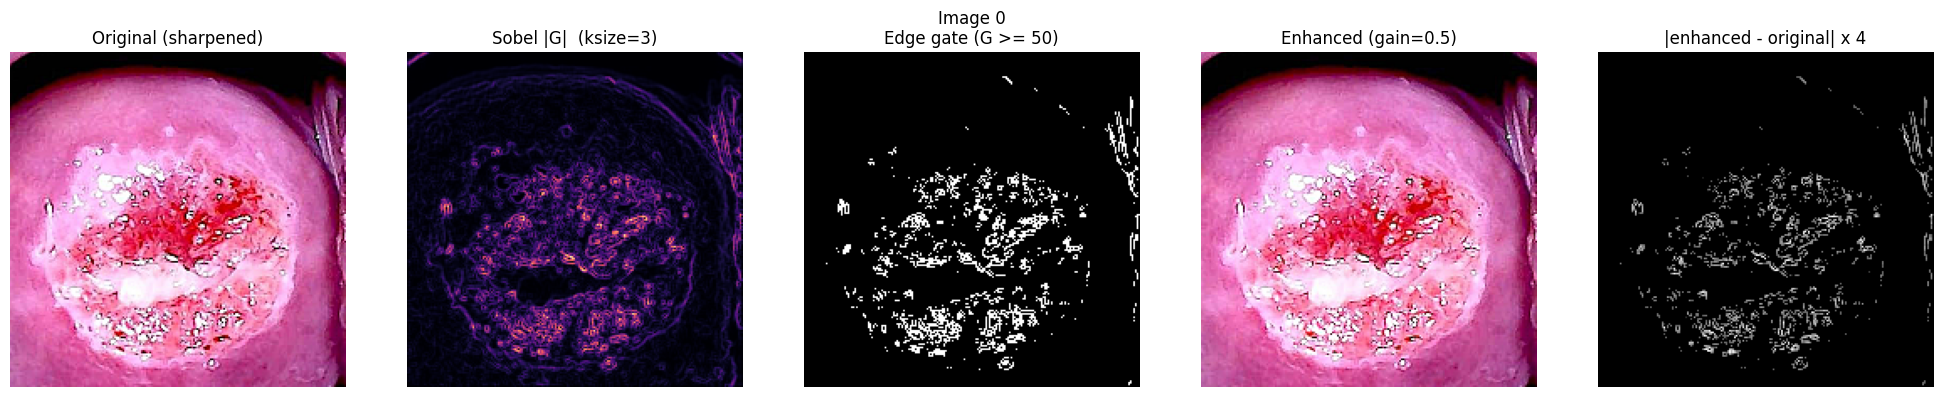

  Image 0: edge coverage in FOV = 7.38%  | G range = [0.0, 180.5]


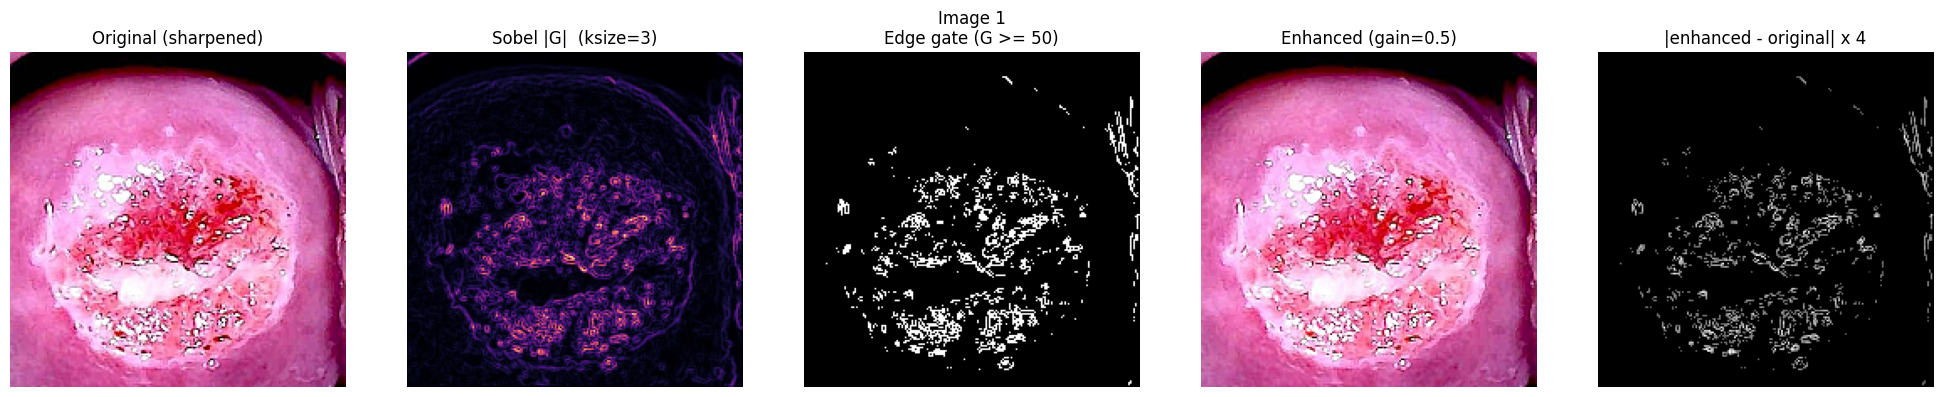

  Image 1: edge coverage in FOV = 7.38%  | G range = [0.0, 180.5]


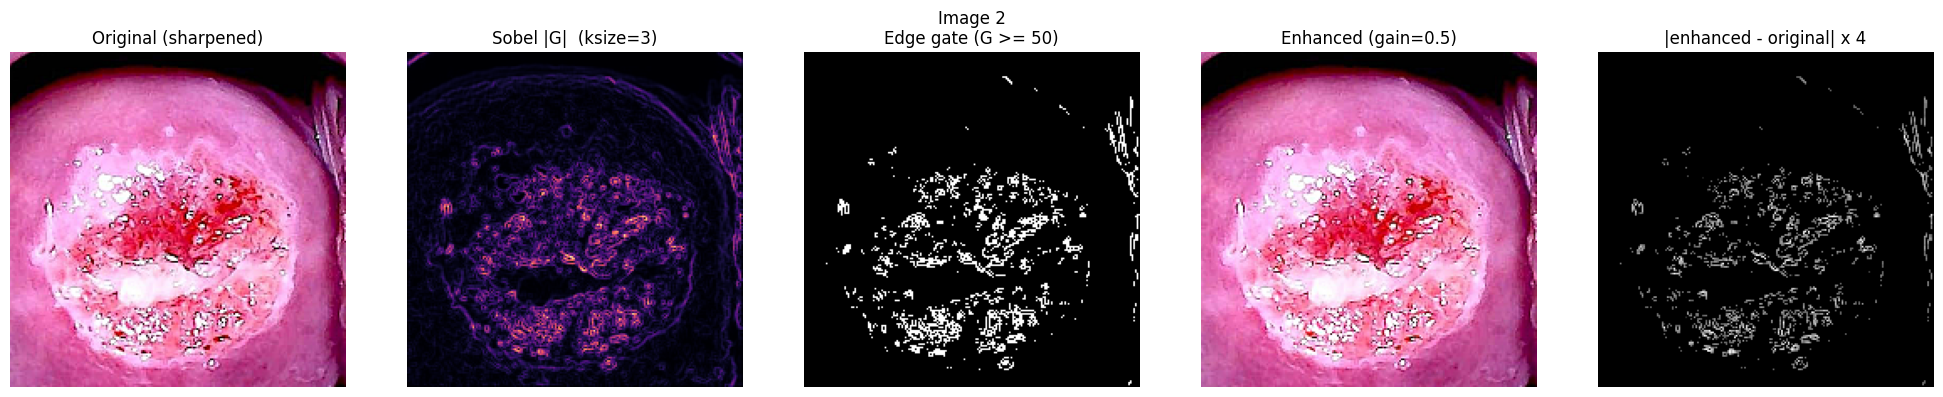

  Image 2: edge coverage in FOV = 7.38%  | G range = [0.0, 180.5]


In [6]:
# ============================================================
# Cell 2.2 -- Visualise the Sobel Edge Detection stages
#   (replaces the former QI-SABP stage figure)
# ============================================================

def show_sobel_stages(rgb_image, title=""):
    """Original | Sobel |G| | edge gate | enhanced | |diff| x 4."""
    out, art = sobel_edge_enhance(rgb_image)
    diff = np.abs(art['img_processed'].astype(np.int16)
                  - art['img_original'].astype(np.int16)).max(axis=2)
    fig, ax = plt.subplots(1, 5, figsize=(20, 4))
    ax[0].imshow(art['img_original'])
    ax[0].set_title("Original (sharpened)")
    ax[1].imshow(art['G'], cmap='magma')
    ax[1].set_title(f"Sobel |G|  (ksize={art['ksize']})")
    ax[2].imshow(art['edge_mask'], cmap='gray')
    ax[2].set_title(f"Edge gate (G >= {art['tau']})")
    ax[3].imshow(art['img_processed'])
    ax[3].set_title(f"Enhanced (gain={art['gain']})")
    ax[4].imshow(np.clip(diff * 4, 0, 255), cmap='gray')
    ax[4].set_title("|enhanced - original| x 4")
    for a in ax:
        a.axis('off')
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    print(f"  {title}: edge coverage in FOV = {100 * art['edge_coverage_fov']:.2f}%  | "
          f"G range = [{art['G'].min():.1f}, {art['G'].max():.1f}]")


if len(X_raw) > 0:
    for _i in range(min(3, len(X_raw))):
        show_sobel_stages(X_raw[_i], title=f"Image {_i}")


# Bridge — hand off Sobel Edge Detection preprocessing to Step 4

Step 4 expects five variables from Steps 1–2:

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|----------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | loader's `X_raw` (sharpened by loader)  |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `sharpen_it=False`        |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                   |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader             |
| `patient`   | patient id (OPTIONAL)                     | `None`                                  |

The bridge no longer needs its own path-dedupe patch: `load_dataset`
dedupes case-insensitively at the source, so `paths_raw` is already
unique.

We also register the technique:

* `SOBEL_DEFAULTS` — fixed module-level configuration (no tuning on a
  single patient).
* `sobel_preprocess(img, params, seed) -> uint8 RGB image` — wraps
  `sobel_edge_enhance`. `params` may override `ksize` / `tau` / `gain`
  per ablation variant. The Sobel operator is fully deterministic, so
  `seed` is accepted only for validator API compatibility.


In [7]:
# ============================================================
# Bridge -- hand off Sobel Edge Detection preprocessing to Step 4.
# ============================================================

# --- Step-1 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1, 2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- Sobel wrapper for Step 4 -----------------------------------------
def sobel_preprocess(img, params=None, seed=0):
    """Sobel Edge Detection preprocessing, exposed to the Step 4 validator.

    Signature: sobel_preprocess(img_uint8_RGB, params_dict, seed) -> uint8 RGB.
    `params` may override ksize / tau / gain (used by the Part B ablation
    variants). `seed` is accepted for validator API compatibility but
    unused: the Sobel operator is fully deterministic.
    """
    p = dict(SOBEL_DEFAULTS)
    if params:
        p.update(params)
    out, _art = sobel_edge_enhance(img, ksize=p["ksize"], tau=p["tau"],
                                   gain=p["gain"])
    return out

# Quick smoke test on the first image
_sm = sobel_preprocess(X_base[0], SOBEL_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"sobel_preprocess smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(sobel_preprocess(X_base[0], SOBEL_DEFAULTS, seed=999), _sm), \
    "sobel_preprocess is not deterministic (it must be)"
print(f"sobel_preprocess() wrapper ready  |  SOBEL_DEFAULTS = {SOBEL_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int) - X_base[0].astype(int)).mean():.3f}")


       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
sobel_preprocess() wrapper ready  |  SOBEL_DEFAULTS = {'ksize': 3, 'tau': 50, 'gain': 0.5}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=1.776


# Part B — Step 4 rewrite: table-only validation with 11 metrics

Single-patient, N distinct clusters (dHash). The frames are NOT
independent. Descriptive only — no p-values, no robustness or
population claims.

**Technique:** Sobel Edge Detection (edge-enhanced RGB output).

**Metrics:** 11 metrics in 4 groups (fidelity, colour, diagnostic
structure, quality/cost). All computed inside the FOV mask only, per
image, against the ORIGINAL image. The former metric 12 (Time, ms) is
REMOVED per the new spec; metric 11 is now reported as **Luma bits** =
nominal bit depth of the output (8.0 — the output stays uint8, no
bit-depth reduction is applied).

| key | metric | group | better |
|-----|--------|-------|--------|
| m1  | PSNR (dB)       | fidelity  | up |
| m2  | SSIM            | fidelity  | up |
| m3  | ΔE76 (CIE76)    | colour    | down |
| m4  | a* correlation  | colour    | up |
| m5  | \|a* shift\|    | colour    | down |
| m6  | Vessel Dice     | structure | up |
| m7  | Edge IoU        | structure | up |
| m8  | Sharpness ratio | quality   | neutral |
| m9  | Noise ratio     | quality   | down |
| m10 | Saturation ratio| quality   | neutral |
| m11 | Luma bits       | cost      | down (constant 8.0) |

**Tables only.** No figures, no plots. T1 (main), T5 (per cluster),
T7 (paired CIs), T8 (region split), T6 (caveats). The former T4 bit
ablation is dropped: the output stays 8-bit, so there are no bit
variants to compare, and the former QI-SABP mask-variant baselines
(uniform / ellipse / shuffled / blob masks, chroma-5, 5-bit floor) are
removed together with the QI-SABP code path.


In [8]:
# ============================================================
# Step 4.1 -- Freeze inputs: load frames, FOV masks, cluster ids.
#
#   NOTE: the former `assert cache_hash == "12f68b681210"` is REMOVED.
#   Part A was rewritten from QI-SABP to Sobel Edge Detection, so the
#   old frozen hash no longer applies. The hash is still computed and
#   printed informationally for provenance tracking.
# ============================================================
import hashlib as _hashlib

# ---- Inputs from Part A / bridge ----
images = X_base        # (N, 200, 200, 3) uint8 RGB, sharpened
images_raw = X_raw     # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([compute_fov_mask(images_raw[i]) for i in range(n_images)])

# dHash clustering (same as the old validator)
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                         for uc in np.unique(cluster_ids)], dtype=int)

# ---- cache_hash (provenance only -- no frozen assert) ----
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}  (provenance only; the frozen QI-SABP "
      f"assert was removed when Part A was rewritten to Sobel)")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


cache_hash = 12f68b681210  (provenance only; the frozen QI-SABP assert was removed when Part A was rewritten to Sobel)
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [9]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions. Computes 11 metrics
#              inside the FOV only, per image.
#
#   Changes vs the former QI-SABP notebook:
#   * m12 (Time, ms) is REMOVED per the new spec -> 11 metrics.
#   * m11 is renamed "Luma bits" and reports the NOMINAL bit depth of
#     the output (set externally by the caller; 8.0 = uint8 RGB).
#   * The corrupted find-replace lines (`a[mask]` -> `aask]`,
#     `METRIC_KEYS = [m[0] ...]` -> `[0] for m ...]`) are regenerated
#     correctly.
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A n B|/(|A|+|B|).
    This has more resolution than a pixel-wise correlation (which is
    0.997-0.999 for every variant)."""
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    denom = float(b_o.sum()) + float(b_p.sum())
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask (same as the old validator)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                  up
      m2  SSIM                       up
      m3  DeltaE76 (CIE76)           down
      m4  a* correlation             up
      m5  |mean a* shift|            down
      m6  Vessel Dice                up
      m7  Edge IoU                   up
      m8  Sharpness ratio (out/in)   neutral (0.9-1.1) / higher
      m9  Noise ratio (out/in)       down
      m10 Saturation ratio (out/in)  neutral (at most 1; capped 999.0)
      m11 Luma bits, nominal         down (set externally; 8.0 = uint8)

    m11 is NOT computed here; it is set by the caller (the nominal bit
    depth depends on the technique's output representation). The former
    m12 (Time, ms) is removed per the new spec.
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                        full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: DeltaE76 (CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                  cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). Measures
    # NEW saturation introduced by the technique, NOT glare removal.
    # Convention: 0/0 -> 1.0 (no change); a zero input count with new
    # specular pixels -> capped at 999.0 (technique created saturation
    # from none; a finite cap keeps means/CIs finite). Most enhanced
    # images never hit this cap on real colposcopy data (glare exists).
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    n_o = float(sp_o[f].sum())
    n_p = float(sp_p[f].sum())
    if n_o == 0:
        m10 = 1.0 if n_p == 0 else 999.0
    else:
        m10 = n_p / n_o
    # m11: Luma bits -- set by the caller (nominal bit depth).
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)

# Metric metadata (key, name, group, better direction) -- 11 metrics.
METRIC_META = [
    ("m1",  "PSNR (dB)",        "fidelity",  "up"),
    ("m2",  "SSIM",             "fidelity",  "up"),
    ("m3",  "ΔE76 (CIE76)",     "colour",    "down"),
    ("m4",  "a* corr",          "colour",    "up"),
    ("m5",  "|a* shift|",       "colour",    "down"),
    ("m6",  "Vessel Dice",      "structure", "up"),
    ("m7",  "Edge IoU",         "structure", "up"),
    ("m8",  "Sharpness ratio",  "quality",   "neutral"),
    ("m9",  "Noise ratio",      "quality",   "down"),
    ("m10", "Saturation ratio", "quality",   "neutral"),
    ("m11", "Luma bits",        "cost",      "down"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 11 metrics (m1..m11). "
      "Time (former m12) removed; m11 = Luma bits (nominal, set by caller).")


step4_validator ready: 11 metrics (m1..m11). Time (former m12) removed; m11 = Luma bits (nominal, set by caller).


In [10]:
# ============================================================
# Step 4.3 -- Compute the 11 metrics for every Sobel variant.
#              Write per-image CSV per technique. Cache processed
#              images for the region tables (no re-runs).
# ============================================================

processed_cache = {}   # (technique, image_idx) -> uint8 RGB

def _csv_name(technique):
    """Filesystem-safe CSV name for a technique."""
    return "".join(c if c.isalnum() else "_" for c in technique)

# Clean stale CSVs (only in SAVE_DIR, never the whole cwd)
for _old in glob.glob(os.path.join(SAVE_DIR, "results_*.csv")):
    os.remove(_old)
    print(f"  Deleted stale {_old}")

variant_frames = {}
for _vname, _vparams in SOBEL_VARIANTS:
    rows = []
    for i in range(n_images):
        orig = images[i]
        proc = sobel_preprocess(orig, _vparams, seed=42 + i)
        m = step4_validator(orig, proc, fov[i])
        m["m11"] = NOMINAL_LUMA_BITS
        m["technique"] = _vname
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows.append(m)
        processed_cache[(_vname, i)] = proc.copy()
        if (i + 1) % 20 == 0 or i == n_images:
            print(f"  [{_vname}] processed {i + 1}/{n_images} images...")
    df_v = pd.DataFrame(rows)
    variant_frames[_vname] = df_v
    _csv = os.path.join(SAVE_DIR, f"results_{_csv_name(_vname)}.csv")
    df_v.to_csv(_csv, index=False)
    print(f"Wrote {_csv} ({len(df_v)} rows)")

DEFAULT_TECH = SOBEL_VARIANTS[0][0]
_df0 = variant_frames[DEFAULT_TECH]
print(f"\nSummary (default variant '{DEFAULT_TECH}'):")
print(f"  mean PSNR       = {_df0['m1'].mean():.2f} dB")
print(f"  mean SSIM       = {_df0['m2'].mean():.4f}")
print(f"  mean DeltaE76   = {_df0['m3'].mean():.3f}")
print(f"  mean a* corr    = {_df0['m4'].mean():.4f}  | mean |a* shift| = {_df0['m5'].mean():.4f}")
print(f"  mean VesselDice = {_df0['m6'].mean():.4f}  | mean Edge IoU  = {_df0['m7'].mean():.4f}")
print(f"  mean Sharpness  = {_df0['m8'].mean():.4f}  | mean Noise     = {_df0['m9'].mean():.4f}")
print(f"  mean Saturation = {_df0['m10'].mean():.4f} | mean Luma bits = {_df0['m11'].mean():.1f}")


  Deleted stale results\results_CannyEdge.csv
  Deleted stale results\results_Identity.csv
  Deleted stale results\results_ROI-Extraction.csv
  [Sobel k3 tau50 (default)] processed 20/128 images...
  [Sobel k3 tau50 (default)] processed 40/128 images...
  [Sobel k3 tau50 (default)] processed 60/128 images...
  [Sobel k3 tau50 (default)] processed 80/128 images...
  [Sobel k3 tau50 (default)] processed 100/128 images...
  [Sobel k3 tau50 (default)] processed 120/128 images...
Wrote results\results_Sobel_k3_tau50__default_.csv (128 rows)
  [Sobel k3 tau30] processed 20/128 images...
  [Sobel k3 tau30] processed 40/128 images...
  [Sobel k3 tau30] processed 60/128 images...
  [Sobel k3 tau30] processed 80/128 images...
  [Sobel k3 tau30] processed 100/128 images...
  [Sobel k3 tau30] processed 120/128 images...
Wrote results\results_Sobel_k3_tau30.csv (128 rows)
  [Sobel k3 tau80] processed 20/128 images...
  [Sobel k3 tau80] processed 40/128 images...
  [Sobel k3 tau80] processed 60/128 

In [11]:
# ============================================================
# Step 4.4 -- Reference row: Identity.
#
#   All former QI-SABP mask-variant baselines (uniform / centre-ellipse
#   / shuffled / blob-random masks, chroma-5, 5-bit floor) are REMOVED:
#   they ran the QI-SABP quantisation code path, which no longer exists
#   in this notebook. Identity is kept as the ideal-value reference.
# ============================================================

for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()

rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["m11"] = NOMINAL_LUMA_BITS
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
_csv_id = os.path.join(SAVE_DIR, "results_Identity.csv")
df_id.to_csv(_csv_id, index=False)
print(f"Wrote {_csv_id} ({len(df_id)} rows)")
print("  Identity is a reference row only (ideal values, not ranked): "
      "PSNR capped ~148 dB, SSIM=1, dE=0, Dice=1, IoU=1, Luma bits=8.")


Wrote results\results_Identity.csv (128 rows)
  Identity is a reference row only (ideal values, not ranked): PSNR capped ~148 dB, SSIM=1, dE=0, Dice=1, IoU=1, Luma bits=8.


In [14]:
# ============================================================
# STEP 4.5 -- Merge existing Sobel variants + Identity
#
# Existing Sobel files:
#   1. results_Sobel_k3_tau80.csv
#   2. results_Sobel_k5_tau30.csv
#   3. results_Sobel_k5_tau50.csv
#
# Identity:
#   C:\CER\results_Identity.csv
#
# Fixed file list: no glob
# Validates row counts, cluster IDs, columns and NaN values.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SAVE_DIR = Path(r"C:\CER\results")
IDENTITY_FILE = Path(r"C:\CER\results_Identity.csv")

# Explicit list of files confirmed in your diagnostic output.
SOBEL_FILES = [
    ("Sobel k3 tau80", SAVE_DIR / "results_Sobel_k3_tau80.csv"),
    ("Sobel k5 tau30", SAVE_DIR / "results_Sobel_k5_tau30.csv"),
    ("Sobel k5 tau50", SAVE_DIR / "results_Sobel_k5_tau50.csv"),
]

EXPECTED_TECHNIQUES = [
    "Sobel k3 tau80",
    "Sobel k5 tau30",
    "Sobel k5 tau50",
    "Identity",
]

OUTPUT_FILE = SAVE_DIR / "merged_sobel_existing_variants_identity.csv"

print("=" * 100)
print("STEP 4.5: MERGE SOBEL VARIANTS + IDENTITY")
print("=" * 100)
print("Sobel results directory:", SAVE_DIR)
print("Identity file:", IDENTITY_FILE)


# ------------------------------------------------------------
# 2. Verify all explicitly listed files
# ------------------------------------------------------------

if not SAVE_DIR.is_dir():
    raise FileNotFoundError(
        f"Sobel results directory does not exist: {SAVE_DIR}"
    )

required_paths = [path for _, path in SOBEL_FILES] + [IDENTITY_FILE]

missing_paths = [
    str(path) for path in required_paths
    if not path.is_file()
]

if missing_paths:
    raise FileNotFoundError(
        "The following required files are missing:\n"
        + "\n".join(missing_paths)
    )

print("\nAll four source files exist.")


# ------------------------------------------------------------
# 3. Read Identity first; use it as the reference
# ------------------------------------------------------------

identity_df = pd.read_csv(IDENTITY_FILE)

if identity_df.empty:
    raise ValueError("Identity CSV is empty.")

required_columns = {"technique", "cluster_id"}
missing_columns = required_columns - set(identity_df.columns)

if missing_columns:
    raise ValueError(
        f"Identity CSV is missing columns: {sorted(missing_columns)}"
    )

identity_labels = (
    identity_df["technique"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
    .tolist()
)

if len(identity_labels) != 1 or identity_labels[0].lower() != "identity":
    raise ValueError(
        f"Expected only Identity rows in the reference CSV. "
        f"Found labels: {identity_labels}"
    )

if identity_df["cluster_id"].isna().any():
    raise ValueError("Identity CSV contains missing cluster IDs.")

n_images = len(identity_df)
reference_cluster_ids = identity_df["cluster_id"].tolist()

print(f"Identity reference rows: {n_images}")
print(
    "Identity reference unique clusters:",
    identity_df["cluster_id"].nunique()
)


# ------------------------------------------------------------
# 4. Read and validate each Sobel CSV
# ------------------------------------------------------------

dfs = []

for expected_technique, path in SOBEL_FILES:

    df = pd.read_csv(path)

    if df.empty:
        raise ValueError(f"{path.name} is empty.")

    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{path.name} is missing columns: "
            f"{sorted(missing_columns)}"
        )

    if len(df) != n_images:
        raise ValueError(
            f"{path.name} has {len(df)} rows; "
            f"Identity has {n_images} rows."
        )

    labels = (
        df["technique"]
        .dropna()
        .astype(str)
        .str.strip()
        .unique()
        .tolist()
    )

    if len(labels) != 1:
        raise ValueError(
            f"{path.name} contains unexpected technique labels: {labels}"
        )

    if df["cluster_id"].isna().any():
        raise ValueError(
            f"{path.name} contains missing cluster IDs."
        )

    # The frame-level cluster IDs must match Identity in the same order.
    if df["cluster_id"].tolist() != reference_cluster_ids:
        raise ValueError(
            f"{path.name}: cluster IDs or their order differ from Identity."
        )

    df = df.copy()

    # Assign a stable label based on the explicitly configured filename.
    # The original label is printed so any discrepancy is visible.
    original_label = labels[0]
    df["technique"] = expected_technique

    dfs.append(df)

    print(
        f"VALIDATED: {path.name} | "
        f"rows={len(df)} | "
        f"original label={original_label}"
    )


# ------------------------------------------------------------
# 5. Validate Identity against the reference
# ------------------------------------------------------------

identity_df = identity_df.copy()
identity_df["technique"] = "Identity"

dfs.append(identity_df)

print(
    f"VALIDATED: {IDENTITY_FILE.name} | "
    f"rows={len(identity_df)} | "
    f"technique=Identity"
)


# ------------------------------------------------------------
# 6. Validate common columns
# ------------------------------------------------------------

reference_columns = set(dfs[0].columns)

for df in dfs[1:]:
    if set(df.columns) != reference_columns:
        raise ValueError(
            "Source CSV columns differ. Cannot concatenate safely."
        )


# ------------------------------------------------------------
# 7. Concatenate
# ------------------------------------------------------------

merged = pd.concat(dfs, ignore_index=True)

actual_techniques = set(merged["technique"].unique())

if actual_techniques != set(EXPECTED_TECHNIQUES):
    raise ValueError(
        f"Technique mismatch: {sorted(actual_techniques)}"
    )

expected_total_rows = n_images * len(EXPECTED_TECHNIQUES)

if len(merged) != expected_total_rows:
    raise ValueError(
        f"Expected {expected_total_rows} merged rows, "
        f"found {len(merged)}."
    )

print("\nMerged row count:", len(merged))
print("Techniques:", EXPECTED_TECHNIQUES)
print("\nRows per technique:")
print(merged.groupby("technique").size())


# ------------------------------------------------------------
# 8. Check metric columns for NaNs and non-finite values
# ------------------------------------------------------------

if "METRIC_KEYS" in globals() and METRIC_KEYS:
    metric_keys = [
        col for col in METRIC_KEYS
        if col in merged.columns
    ]
else:
    excluded = {
        "technique",
        "cluster_id",
        "image_id",
        "image_index",
        "frame_id",
        "index",
        "Unnamed: 0",
    }

    metric_keys = [
        col for col in merged.columns
        if col not in excluded
        and pd.api.types.is_numeric_dtype(merged[col])
    ]

if not metric_keys:
    raise ValueError("No metric columns were identified.")

nan_counts = merged[metric_keys].isna().sum()
nan_counts = nan_counts[nan_counts > 0]

if not nan_counts.empty:
    raise ValueError(
        "NaN values found in metric columns:\n"
        f"{nan_counts.to_dict()}\n"
        "Inspect the source files or the metric-generation code."
    )

nonfinite_counts = {}

for col in metric_keys:
    values = pd.to_numeric(merged[col], errors="raise").to_numpy(
        dtype=float
    )
    count = int((~np.isfinite(values)).sum())

    if count:
        nonfinite_counts[col] = count

if nonfinite_counts:
    raise ValueError(
        "Infinite or non-finite values found:\n"
        f"{nonfinite_counts}"
    )

print(f"\nPASS: No NaN values in {len(metric_keys)} metric columns.")
print("PASS: No infinite metric values.")


# ------------------------------------------------------------
# 9. Save merged output
# ------------------------------------------------------------

merged.to_csv(OUTPUT_FILE, index=False)

if not OUTPUT_FILE.is_file():
    raise IOError(f"Output file was not created: {OUTPUT_FILE}")

print("\n" + "=" * 100)
print("STEP 4.5 COMPLETED SUCCESSFULLY")
print("=" * 100)
print("Saved:", OUTPUT_FILE)
print("Total rows:", len(merged))
print("Rows per technique:", n_images)
print("Number of techniques:", merged["technique"].nunique())
print("Metric columns checked:", len(metric_keys))
print("Output shape:", merged.shape)

display(merged.head())

STEP 4.5: MERGE SOBEL VARIANTS + IDENTITY
Sobel results directory: C:\CER\results
Identity file: C:\CER\results_Identity.csv

All four source files exist.
Identity reference rows: 128
Identity reference unique clusters: 7
VALIDATED: results_Sobel_k3_tau80.csv | rows=128 | original label=Sobel k3 tau80
VALIDATED: results_Sobel_k5_tau30.csv | rows=128 | original label=Sobel k5 tau30
VALIDATED: results_Sobel_k5_tau50.csv | rows=128 | original label=Sobel k5 tau50
VALIDATED: results_Identity.csv | rows=128 | technique=Identity


ValueError: Source CSV columns differ. Cannot concatenate safely.

In [ ]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap
#              (n_clusters clusters, 2000 resamples, fixed seed).
#              Label: "within-patient, N clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (2000 resamples).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.")


In [ ]:
# ============================================================
# Step 4.7 -- Statistics: every Sobel variant vs Identity, and every
#              non-default variant vs the default config, per key
#              metric. Uses paired difference per cluster (N values) +
#              bootstrap CI. Reports "CI excludes 0: yes/no".
#              Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    common = tech_cm.index.intersection(ref_cm.index)
    diff = (tech_cm.loc[common] - ref_cm.loc[common]).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Key metrics for the paired comparison (colour / structure / quality
# deltas; PSNR/SSIM/Luma-bits differences vs Identity are reported in
# T1 and are not interesting paired contrasts).
key_metrics = ["m3", "m5", "m6", "m7", "m9"]

stat_rows = []
id_df = merged[merged["technique"] == "Identity"]
default_df = merged[merged["technique"] == DEFAULT_TECH]

# Every Sobel variant vs Identity (key metrics only).
for vt in [t for t in techniques if t != "Identity"]:
    v_df = merged[merged["technique"] == vt]
    for mk in key_metrics:
        md, lo, hi, ex = _paired_cluster_diff_ci(v_df, id_df, mk)
        stat_rows.append({
            "metric": METRIC_NAMES[mk], "comparison": f"{vt} vs Identity",
            "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
            "CI_excludes_0": "yes" if ex else "no",
        })

# Every non-default Sobel variant vs the default config (ablation contrast).
for vt in [t for t in techniques if t not in ("Identity", DEFAULT_TECH)]:
    v_df = merged[merged["technique"] == vt]
    for mk in key_metrics:
        md, lo, hi, ex = _paired_cluster_diff_ci(v_df, default_df, mk)
        stat_rows.append({
            "metric": METRIC_NAMES[mk], "comparison": f"{vt} vs {DEFAULT_TECH}",
            "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
            "CI_excludes_0": "yes" if ex else "no",
        })

stat_df = pd.DataFrame(stat_rows)
print("Statistics done. Every Sobel variant vs Identity + non-default vs default, "
      "key metrics only.")
print("  Descriptive, no significance claim. Within-patient clusters.")


In [ ]:
# ============================================================
# Print tables T1, T5, T7, T8, T6.
#   T2 (ranks) and T3 (Pareto) belong in the multi-technique merge.
#   T4 (bit ablation) is dropped: the Sobel output stays 8-bit, so
#   there are no bit variants to compare (Luma bits = 8.0 everywhere).
#
#   The fixed region used by T5/T8 is the DEFAULT Sobel edge gate
#   (G >= SOBEL_TAU with ksize=SOBEL_KSIZE on the ORIGINAL image,
#   intersected with the FOV) -- one fixed region for ALL variants.
# ============================================================

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

# ---- Fixed region: default Sobel edge gate per image ----
_sobel_gate = {}
for i in range(n_images):
    _g = sobel_edge_map(images[i], tau=SOBEL_TAU, ksize=SOBEL_KSIZE)
    _sobel_gate[i] = _g & fov[i]

# ---- T1 Main ----
print("=" * 110)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, "
      f"{n_clusters} clusters, NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("  Luma bits is the NOMINAL output bit depth (8.0 = uint8; constant by design).")
print("=" * 110)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T5 Per cluster: dE inside vs outside the Sobel edge gate ----
print()
print("=" * 110)
print(f"T5 PER CLUSTER  (dE76 inside vs outside the default Sobel edge gate; "
      f"{n_clusters} clusters)")
print("  Inside = edge-gate pixels (enhanced); outside = rest of the FOV.")
print("=" * 110)
t5_rows = []
for uc in np.unique(cluster_ids):
    idxs = np.where(cluster_ids == uc)[0]
    for tech_name in techniques:
        de_ins, de_outs = [], []
        for i in idxs:
            orig = images[i]
            proc = processed_cache.get((tech_name, i))
            if proc is None:
                continue
            inside = _sobel_gate[i]
            outside = fov[i] & ~inside
            if inside.any() and outside.any():
                de_map = _deltaE_fn(_rgb2lab_fn(orig), _rgb2lab_fn(proc))
                de_ins.append(float(de_map[inside].mean()))
                de_outs.append(float(de_map[outside].mean()))
        t5_rows.append({"cluster": int(uc), "technique": tech_name,
                        "dE_inside": np.mean(de_ins) if de_ins else float('nan'),
                        "dE_outside": np.mean(de_outs) if de_outs else float('nan')})
t5_df = pd.DataFrame(t5_rows)
print(t5_df.round(4).to_string(index=False))

# ---- T7 Paired CIs + meaningful flag ----
print()
print("=" * 110)
print("T7 PAIRED CIs  (each Sobel variant vs Identity, and non-default vs default; "
      "key metrics; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05")
print("=" * 110)
_meaningful_thresh = {"ΔE76 (CIE76)": 0.5, "|a* shift|": 0.2, "Vessel Dice": 0.01,
                      "Edge IoU": 0.02, "Noise ratio": 0.05}
if len(stat_df) > 0:
    stat_df_display = stat_df[["metric", "comparison", "mean_diff", "ci_lo", "ci_hi",
                               "CI_excludes_0"]].copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0) else "no",
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T8 Region-split for ALL techniques + risk metrics ----
print()
print("=" * 110)
print("T8 REGION-SPLIT  (dE / edge IoU / vessel Dice / risk metrics inside vs outside "
      "the default Sobel edge gate)")
print("  Same fixed region (default Sobel gate on the original) for ALL techniques.")
print("=" * 110)

t8_rows = []
for tech_name in techniques:
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        hm = _sobel_gate[i]
        inside = hm
        outside = fov_i & ~hm
        if not (inside.any() and outside.any()):
            continue
        proc = processed_cache.get((tech_name, i))
        if proc is None:
            continue
        # dE, split into dL* and da*b*.
        lab_o = _rgb2lab_fn(orig)
        lab_p = _rgb2lab_fn(proc)
        de_map = _deltaE_fn(lab_o, lab_p)
        de_in = float(de_map[inside].mean())
        de_out = float(de_map[outside].mean())
        dL_map = np.abs(lab_o[..., 0] - lab_p[..., 0])
        dab_map = np.sqrt((lab_o[..., 1] - lab_p[..., 1]) ** 2 +
                          (lab_o[..., 2] - lab_p[..., 2]) ** 2)
        dL_in = float(dL_map[inside].mean())
        dL_out = float(dL_map[outside].mean())
        dab_in = float(dab_map[inside].mean())
        dab_out = float(dab_map[outside].mean())
        e_o = _edge_map(orig)
        e_p = _edge_map(proc)
        eiou_in = _edge_iou(e_o, e_p, inside)
        eiou_out = _edge_iou(e_o, e_p, outside)
        vd_in = _vessel_dice(orig, proc, inside, top_pct=10)
        vd_out = _vessel_dice(orig, proc, outside, top_pct=10)
        de_all = de_map[fov_i]
        pct_de_gt5_all = float((de_all > 5).mean())
        de_outside_arr = de_map[outside]
        pct_de_gt5_out = float((de_outside_arr > 5).mean())
        de_p95_all = float(np.percentile(de_all, 95))
        de_p95_out = float(np.percentile(de_outside_arr, 95))
        hm_erode6 = ndimage.binary_erosion(hm, iterations=6)
        hm_dilate10 = ndimage.binary_dilation(hm, iterations=10)
        band = (hm_dilate10 & ~hm_erode6) & fov_i
        de_band = float(de_map[band].mean()) if band.any() else float('nan')
        t8_rows.append({
            "technique": tech_name,
            "dE_inside": de_in, "dE_outside": de_out,
            "dL_inside": dL_in, "dL_outside": dL_out,
            "dab_inside": dab_in, "dab_outside": dab_out,
            "edgeIoU_inside": eiou_in, "edgeIoU_outside": eiou_out,
            "vesselDice_inside": vd_in, "vesselDice_outside": vd_out,
            "pct_dE>5_all": pct_de_gt5_all,
            "pct_dE>5_outside": pct_de_gt5_out,
            "dE_p95_all": de_p95_all,
            "dE_p95_outside": de_p95_out,
            "dE_boundary_band": de_band,
        })

if t8_rows:
    t8_df = pd.DataFrame(t8_rows)
    t8_agg = t8_df.groupby("technique").mean(numeric_only=True)
    print(t8_agg.round(4).to_string())
    print()
    print("  Interpretation: the Sobel gate marks pixels with strong local")
    print("  gradients, so dE_inside should be HIGHER than dE_outside (the")
    print("  enhancement is concentrated exactly on the gated edge pixels).")
    print("  dL* is lightness error; da*b* is chroma error -- most of the")
    print("  enhancement error should be dL* (brightness), not da*b* (colour).")
    print("  pct_dE>5 and dE_p95 are risk metrics: high values OUTSIDE the gate")
    print("  would mean visible colour shift away from the edges (not expected:")
    print("  the FOV guard copies non-gated pixels verbatim).")
else:
    print("  (T8 failed to compute -- no image had edge-gate pixels)")

# ---- T6 Caveats ----
print()
print("=" * 110)
print("T6 CAVEATS  (one line each)")
print("=" * 110)
caveats = [
    f"Single patient; {n_clusters} distinct frames (dHash); {n_images} frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "No lesion masks on the real dataset; lesion dE and lesion CNR are not evaluated (disabled hook).",
    "Luma bits (m11) is the NOMINAL bit depth of the output: 8.0 for every row (uint8 RGB in, uint8 RGB out; no bit-depth reduction). The former T4 bit ablation is dropped.",
    "The Sobel output is an ENHANCEMENT, not a compression: PSNR/SSIM/dE76 measure the added edge enhancement, not reconstruction loss. A lower PSNR means a stronger (more aggressive) enhancement.",
    "Edge IoU (m7) penalises edge enhancement by construction: boosting gradient magnitude shifts the Canny(50,150) response near gated edges, so a lower IoU is expected and does not mean lost anatomy.",
    "Sharpness ratio (m8) > 1 is expected: adding gradient magnitude raises the Laplacian variance.",
    "Saturation ratio (m10) = output/input specular (V>=250, S<=25) pixel count inside the FOV; 0/0 defined as 1.0; a zero input count with new specular pixels is capped at 999.0 (the additive enhancement can clip bright edges to white).",
    "Vessel Dice (m6): Dice of top 10% Frangi pixels, 2*|A n B|/(|A|+|B|).",
    "Noise ratio (m9): 1.4826*MAD of the Gaussian high-pass in smooth areas (bottom 30% Sobel gradient), out/in.",
    f"95% CI is WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.",
    "dE76 (CIE76), not CIEDE2000.",
    "Identity is a reference row only (not ranked). Its PSNR is capped (~148 dB), SSIM=1, dE=0, Dice=1, IoU=1.",
    "T7 meaningful flag: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05. With few clusters, tiny differences 'exclude 0' but may not be practically meaningful.",
    "All former QI-SABP mask-variant baselines (uniform / ellipse / shuffled / blob, chroma-5, 5-bit floor) are REMOVED together with the QI-SABP code path.",
    "Time (former m12) is removed per the new 11-metric spec.",
    "T2 (ranks), T3 (Pareto) and T4 (bit ablation) are not printed in this notebook (multi-technique merge / not applicable).",
]
for c in caveats:
    print(f"  - {c}")
